Name- Ujjawal chauhan
rollno - 62
subject-Mastery in Data Analytics and Visualizations and Career Advancement
 LABSHEET - 09


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from scipy.stats import chi2_contingency

%matplotlib inline

In [ ]:
import pandas as pd

df = pd.read_csv("/content/WA_Fn-UseC_-HR-Employee-Attrition.csv")

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
for i, col in enumerate(df.columns, 1):
    print(i, ":", col)

Dataset Shape: (1470, 35)

Column Names:
1 : Age
2 : Attrition
3 : BusinessTravel
4 : DailyRate
5 : Department
6 : DistanceFromHome
7 : Education
8 : EducationField
9 : EmployeeCount
10 : EmployeeNumber
11 : EnvironmentSatisfaction
12 : Gender
13 : HourlyRate
14 : JobInvolvement
15 : JobLevel
16 : JobRole
17 : JobSatisfaction
18 : MaritalStatus
19 : MonthlyIncome
20 : MonthlyRate
21 : NumCompaniesWorked
22 : Over18
23 : OverTime
24 : PercentSalaryHike
25 : PerformanceRating
26 : RelationshipSatisfaction
27 : StandardHours
28 : StockOptionLevel
29 : TotalWorkingYears
30 : TrainingTimesLastYear
31 : WorkLifeBalance
32 : YearsAtCompany
33 : YearsInCurrentRole
34 : YearsSinceLastPromotion
35 : YearsWithCurrManager


In [ ]:
print("First 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

First 5 Rows:


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  Jo

In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
df = df.drop(
    ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber'],
    axis=1
)

print("New Dataset Shape:", df.shape)

New Dataset Shape: (1470, 31)


In [ ]:
for col in df.columns:
    print("\n", col)
    print(df[col].unique()[:10])


 Age
[41 49 37 33 27 32 59 30 38 36]

 Attrition
['Yes' 'No']

 BusinessTravel
['Travel_Rarely' 'Travel_Frequently' 'Non-Travel']

 DailyRate
[1102  279 1373 1392  591 1005 1324 1358  216 1299]

 Department
['Sales' 'Research & Development' 'Human Resources']

 DistanceFromHome
[ 1  8  2  3 24 23 27 16 15 26]

 Education
[2 1 4 3 5]

 EducationField
['Life Sciences' 'Other' 'Medical' 'Marketing' 'Technical Degree'
 'Human Resources']

 EnvironmentSatisfaction
[2 3 4 1]

 Gender
['Female' 'Male']

 HourlyRate
[94 61 92 56 40 79 81 67 44 84]

 JobInvolvement
[3 2 4 1]

 JobLevel
[2 1 3 4 5]

 JobRole
['Sales Executive' 'Research Scientist' 'Laboratory Technician'
 'Manufacturing Director' 'Healthcare Representative' 'Manager'
 'Sales Representative' 'Research Director' 'Human Resources']

 JobSatisfaction
[4 2 3 1]

 MaritalStatus
['Single' 'Married' 'Divorced']

 MonthlyIncome
[5993 5130 2090 2909 3468 3068 2670 2693 9526 5237]

 MonthlyRate
[19479 24907  2396 23159 16632 11864  9964 1

In [ ]:
categorical_cols = df.select_dtypes(
    include=['object']
).columns

print("Categorical Columns:")
print(list(categorical_cols))

Categorical Columns:
['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [ ]:
df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True
)

print("Encoded Dataset Shape:", df_encoded.shape)

Encoded Dataset Shape: (1470, 45)


In [ ]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.0,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.0,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.0,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.0,3.0,4.00,5.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.0,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.0,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.0,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.0,2.0,3.00,5.0
JobSatisfaction,1470.0,2.728571,1.102846,1.0,2.0,3.0,4.00,4.0
MonthlyIncome,1470.0,6502.931293,4707.956783,1009.0,2911.0,4919.0,8379.00,19999.0


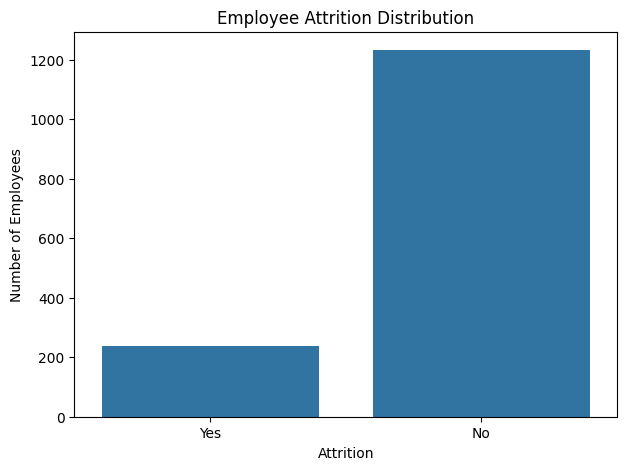

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Attrition'
)

plt.title('Employee Attrition Distribution')
plt.xlabel('Attrition')
plt.ylabel('Number of Employees')

plt.show()

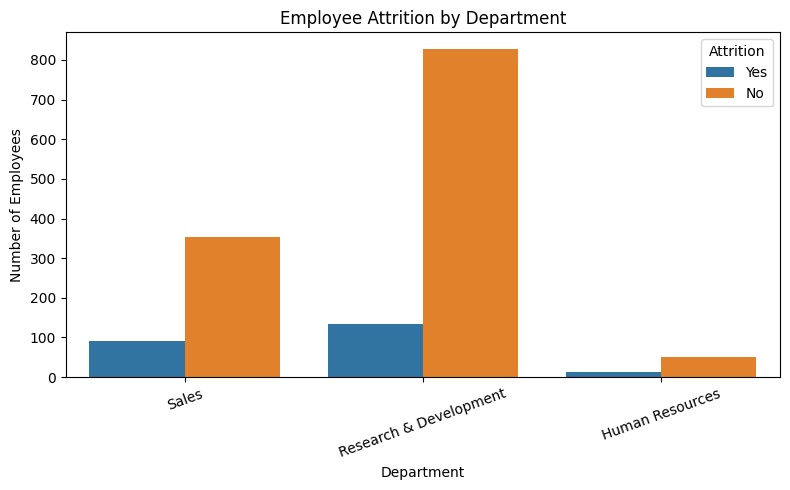

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Department',
    hue='Attrition'
)

plt.title('Employee Attrition by Department')
plt.xlabel('Department')
plt.ylabel('Number of Employees')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

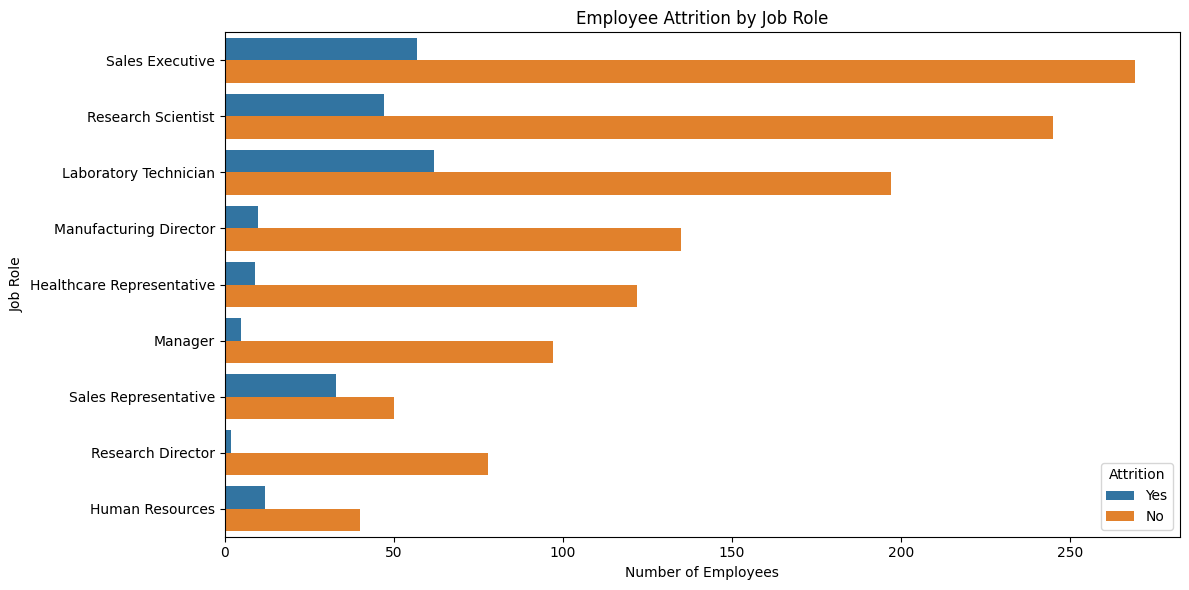

In [ ]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y='JobRole',
    hue='Attrition'
)

plt.title('Employee Attrition by Job Role')
plt.xlabel('Number of Employees')
plt.ylabel('Job Role')

plt.tight_layout()
plt.show()

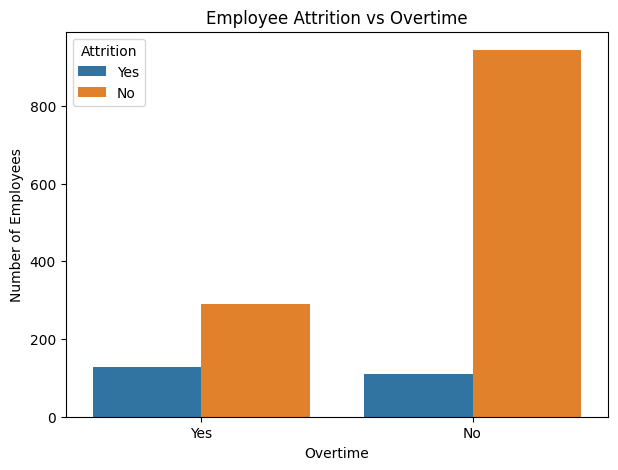

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='OverTime',
    hue='Attrition'
)

plt.title('Employee Attrition vs Overtime')
plt.xlabel('Overtime')
plt.ylabel('Number of Employees')

plt.show()

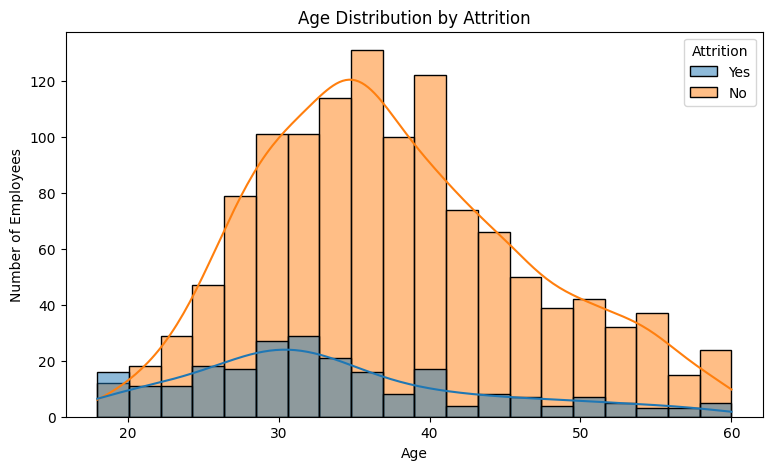

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='Age',
    hue='Attrition',
    bins=20,
    kde=True
)

plt.title('Age Distribution by Attrition')
plt.xlabel('Age')
plt.ylabel('Number of Employees')

plt.show()

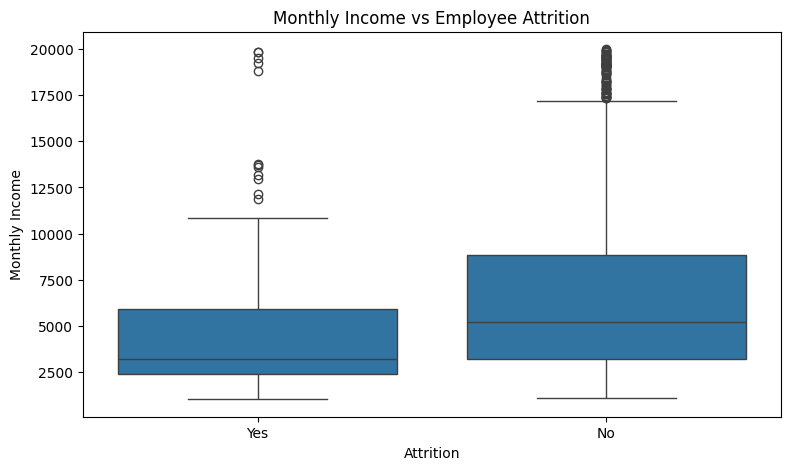

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Attrition',
    y='MonthlyIncome'
)

plt.title('Monthly Income vs Employee Attrition')
plt.xlabel('Attrition')
plt.ylabel('Monthly Income')

plt.show()

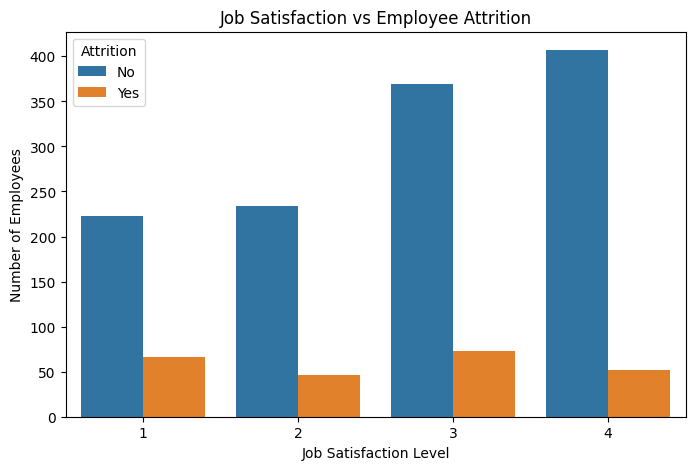

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='JobSatisfaction',
    hue='Attrition'
)

plt.title('Job Satisfaction vs Employee Attrition')
plt.xlabel('Job Satisfaction Level')
plt.ylabel('Number of Employees')

plt.show()

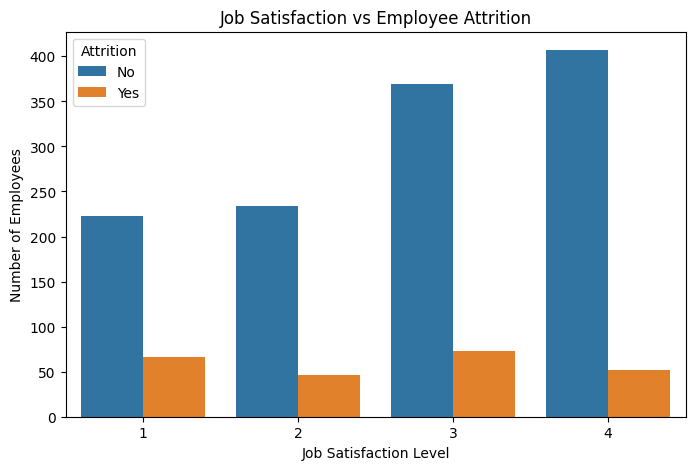

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='JobSatisfaction',
    hue='Attrition'
)

plt.title('Job Satisfaction vs Employee Attrition')
plt.xlabel('Job Satisfaction Level')
plt.ylabel('Number of Employees')

plt.show()

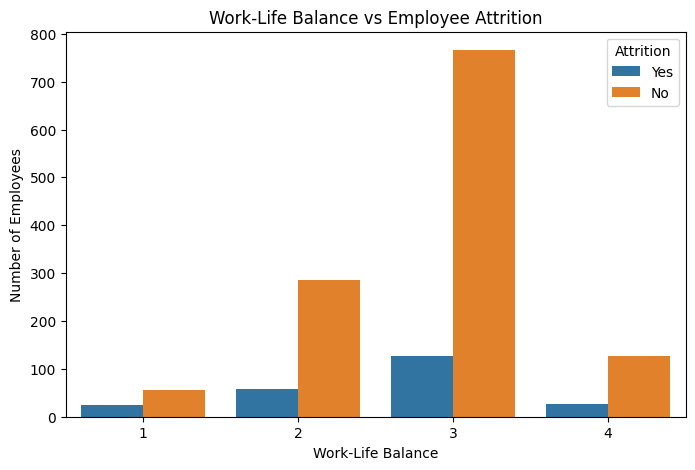

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='WorkLifeBalance',
    hue='Attrition'
)

plt.title('Work-Life Balance vs Employee Attrition')
plt.xlabel('Work-Life Balance')
plt.ylabel('Number of Employees')

plt.show()

In [ ]:
# Ensure Attrition column exists
if 'Attrition' not in df_encoded.columns:
    df_encoded['Attrition'] = df['Attrition'].values

# Convert Attrition into numeric form
df_encoded['Attrition'] = pd.to_numeric(
    df_encoded['Attrition'],
    errors='coerce'
)

# Calculate correlations
corr_matrix = df_encoded.corr(numeric_only=True)

if 'Attrition' in corr_matrix.columns:
    corr = corr_matrix['Attrition'].sort_values(ascending=False)

    print("Top Factors Related to Attrition:")
    print(corr.head(10))
else:
    print("Error: Attrition column is still missing.")

Top Factors Related to Attrition:
Age                       NaN
DailyRate                 NaN
DistanceFromHome          NaN
Education                 NaN
EnvironmentSatisfaction   NaN
HourlyRate                NaN
JobInvolvement            NaN
JobLevel                  NaN
JobSatisfaction           NaN
MonthlyIncome             NaN
Name: Attrition, dtype: float64


In [ ]:
table = pd.crosstab(df['OverTime'], df['Attrition'])
chi2, p, dof, expected = chi2_contingency(table)

print("Chi-Square:", chi2)
print("p-value:", p)

if p < 0.05:
    print("Significant association between Overtime and Attrition.")
else:
    print("No significant association.")

Chi-Square: 87.56429365828768
p-value: 8.15842372153832e-21
Significant association between Overtime and Attrition.


In [ ]:
X = df_encoded.drop('Attrition_Yes', axis=1)
y = df_encoded['Attrition_Yes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = DecisionTreeClassifier(max_depth=5, random_state=42)
model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


Accuracy : 0.8333333333333334
Precision: 0.4444444444444444
Recall   : 0.1702127659574468
F1 Score : 0.24615384615384617


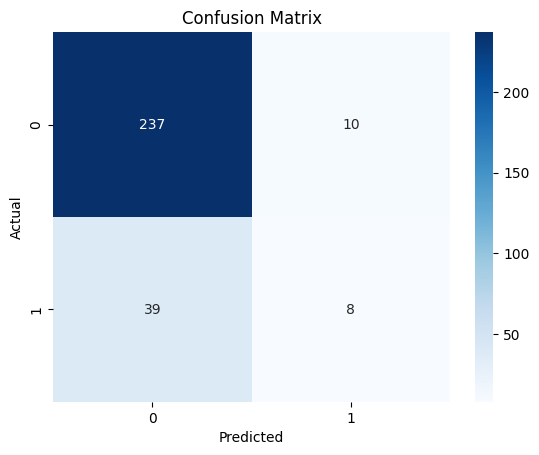

In [ ]:
y_pred = model.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Top 10 Important Features:
TotalWorkingYears             0.227763
OverTime_Yes                  0.147191
DailyRate                     0.113395
MonthlyIncome                 0.108999
Age                           0.100578
MaritalStatus_Single          0.057004
JobRole_Research Scientist    0.049864
NumCompaniesWorked            0.042111
HourlyRate                    0.038135
YearsInCurrentRole            0.033556
dtype: float64


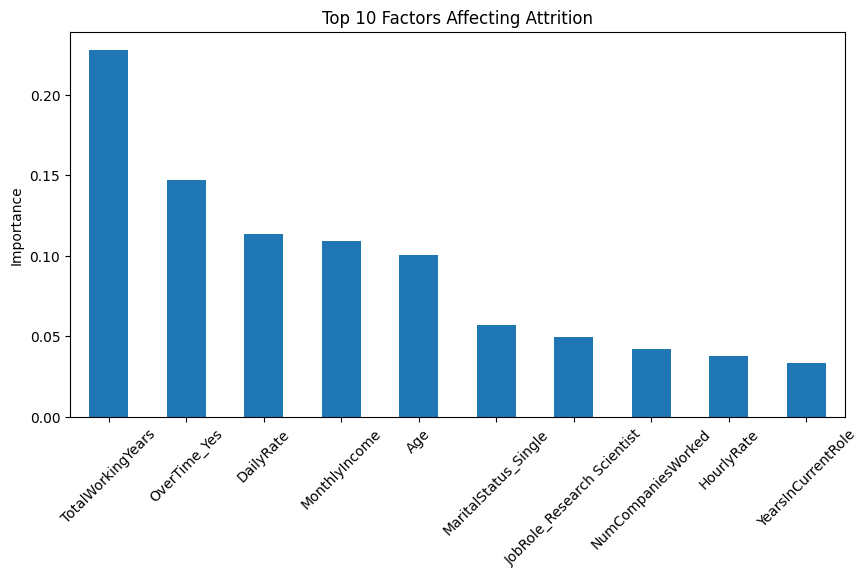

In [ ]:
importance = pd.Series(
    model.feature_importances_, index=X.columns
).sort_values(ascending=False)

print("Top 10 Important Features:")
print(importance.head(10))

importance.head(10).plot(kind='bar', figsize=(10,5))
plt.title("Top 10 Factors Affecting Attrition")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.show()

In [ ]:
print("FINAL BUSINESS INSIGHTS")
print("-----------------------")

print("Total Employees:", len(df))
print("Attrition Rate:",
      round(df_encoded['Attrition_Yes'].mean()*100, 2), "%")

# To get the highest attrition job role and department, we first need to map 'Yes' to 1 and 'No' to 0
df['Attrition_Numeric'] = df['Attrition'].map({'Yes': 1, 'No': 0})

print("Highest Attrition Job Role:",
      df.groupby('JobRole')['Attrition_Numeric'].mean().idxmax())

print("Highest Attrition Department:",
      df.groupby('Department')['Attrition_Numeric'].mean().idxmax())

print("\nCONCLUSION:")
print("Data analysis and Decision Tree classification were used")
print("to identify factors related to employee attrition.")
print("These insights can help HR improve employee retention.")

FINAL BUSINESS INSIGHTS
-----------------------
Total Employees: 1470
Attrition Rate: 16.12 %
Highest Attrition Job Role: Sales Representative
Highest Attrition Department: Sales

CONCLUSION:
Data analysis and Decision Tree classification were used
to identify factors related to employee attrition.
These insights can help HR improve employee retention.
